In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.pyplot import figure
import math
from haversine import haversine, Unit
from datetime import datetime, timedelta
from sklearn.metrics import silhouette_score

from LSTM.Clustering_LSTM import training_clustered

In [20]:
training = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/training.csv").drop(columns=["Unnamed: 0"])
val = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/validation.csv").drop(columns=["Unnamed: 0"])

# LCSS calculation

In [21]:
from pyproj import Transformer

df = training

tf = Transformer.from_crs("EPSG:4326", "EPSG:32635", always_xy=True)  # zone 35N covers 24-30°E

df = (df.sort_values(['trajectory_ID', 'UTC'])
        .drop_duplicates(['trajectory_ID', 'UTC']))


## Arc-length resampling
#Interpolate each trajectory at N equally spaced distances along its path.

def resample_xy(xy, n=100):
    seg = np.linalg.norm(np.diff(xy, axis=0), axis=1)
    s = np.r_[0, np.cumsum(seg)]
    if s[-1] == 0:
        return None
    u = np.linspace(0, s[-1], n)
    return np.column_stack([np.interp(u, s, xy[:, 0]),
                            np.interp(u, s, xy[:, 1])])

N = 100
trajs, ids = [], []
for tid, g in df.groupby('trajectory_ID'):
    if g is None or len(g) < 10:
        continue
    x, y = tf.transform(g['LON'].values, g['LAT'].values)
    xy = np.column_stack([x, y])            # m
    path_len = np.linalg.norm(np.diff(xy, axis=0), axis=1).sum()
    if path_len < 5000:                                  # m, tune to your data
        continue
    r = resample_xy(xy, N)
    if r is not None:
        trajs.append(r); ids.append(tid)

X = np.stack(trajs)         # shape (n_traj, N, 2)
traj_ids = ids

In [22]:
from numba import njit

@njit
def lcss_similarity_numba(traj_a, traj_b, epsilon, delta):

    n = traj_a.shape[0]
    m = traj_b.shape[0]

    prev = np.zeros(m + 1, dtype=np.int16)
    curr = np.zeros(m + 1, dtype=np.int16)

    epsilon_sq = epsilon * epsilon

    for i in range(1, n + 1):

        for j in range(m + 1):
            curr[j] = 0

        j_start = max(1, i - delta)
        j_end = min(m, i + delta)

        for j in range(j_start, j_end + 1):

            dx = traj_a[i - 1, 0] - traj_b[j - 1, 0]
            dy = traj_a[i - 1, 1] - traj_b[j - 1, 1]

            distance_sq = dx * dx + dy * dy

            if distance_sq <= epsilon_sq:

                curr[j] = prev[j - 1] + 1

            else:

                if prev[j] >= curr[j - 1]:
                    curr[j] = prev[j]
                else:
                    curr[j] = curr[j - 1]

        temp = prev
        prev = curr
        curr = temp

    return prev[m] / min(n, m)

In [23]:
EPSILON = 8000
DELTA = 5

# ==========================================
# Calculate distance matrix
# ==========================================

n = len(X)

D_lcss = np.zeros(
    (n, n),
    dtype=np.float64
)

for i in range(n):

    if i % 500 == 0:
        print(f"{i}/{n}")

    for j in range(i + 1, n):

        similarity = lcss_similarity_numba(
            X[i],
            X[j],
            EPSILON,
            DELTA
        )

        distance = 1.0 - similarity

        D_lcss[i, j] = distance
        D_lcss[j, i] = distance

0/2635
500/2635
1000/2635
1500/2635
2000/2635
2500/2635


In [24]:
import hdbscan
min_samples = 30
min_cluster_size = 50

clusterer = hdbscan.HDBSCAN(
    metric="precomputed",
    min_cluster_size=min_cluster_size,
    min_samples=min_samples,
    cluster_selection_method="eom"
)

labels_lcss = clusterer.fit_predict(D_lcss)

In [25]:
unique, counts = np.unique(
labels_lcss,
return_counts=True
)

print(
    pd.DataFrame({
        "cluster": unique,
        "count": counts
    })
)

n_clusters = len(set(labels_lcss)) - (
    1 if -1 in labels_lcss else 0
)

noise_fraction = np.mean(labels_lcss == -1)

   cluster  count
0       -1   1451
1        0    100
2        1    199
3        2     90
4        3    149
5        4    130
6        5    129
7        6     94
8        7    214
9        8     79


In [26]:
from sklearn.metrics import silhouette_score

mask = labels_lcss != -1
labels_clustered = labels_lcss[mask]
D = D_lcss
D_clustered = D[mask][:, mask]

sil = silhouette_score(
    D_clustered,
    labels_clustered,
    metric="precomputed"
)

print("Silhouette:", sil)

Silhouette: 0.5099758506300105


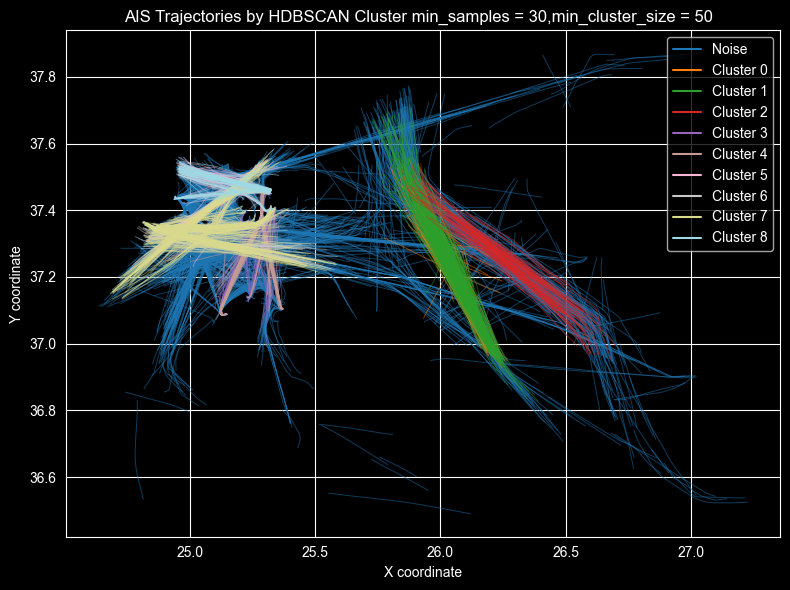

In [27]:
#df = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/df_5.csv").drop(columns=['Unnamed: 0'])
labels = labels_lcss

cluster_mapping = pd.DataFrame({
    "trajectory_ID": traj_ids,
    "cluster": labels
})

df_plot = df.merge(
    cluster_mapping,
    on="trajectory_ID",
    how="left"
)

fig, ax = plt.subplots(figsize=(8, 6))

clusters = sorted(df_plot["cluster"].dropna().unique())

# Generate colors
colors = plt.cm.tab20(np.linspace(0, 1, len(clusters)))

for cluster, color in zip(clusters, colors):

    cluster_data = df_plot[df_plot["cluster"] == cluster]
    # Plot each trajectory separately
    for trajectory_id, traj in cluster_data.groupby("trajectory_ID"):

        traj = traj.sort_values("TIMESTAMP")

        ax.plot(
            traj["LON"],
            traj["LAT"],
            color=color,
            linewidth=0.7,
            alpha=0.5
        )

    # Legend
    if cluster == -1:
        label = "Noise"
    else:
        label = f"Cluster {cluster}"

    ax.plot([], [], color=color, label=label)

ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_title(f"AIS Trajectories by HDBSCAN Cluster min_samples = {min_samples},min_cluster_size = {min_cluster_size}  ")
ax.legend()

plt.tight_layout()
plt.show()

In [31]:
df_plot.set_index("cluster").reset_index().to_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/training_clustered.csv")

In [32]:
training_clustered = pd.read_csv("C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/training_clustered.csv")

# Assign clusters to validation trajectories

In [39]:
from  WindowFunctions import make_val_windows

In [40]:
df = val.sort_values(["trajectory_ID", "TIMESTAMP"], ascending=[True, True])

features = ["LON", "LAT","SOG","COG"]
target_features = ["LON", "LAT"]

input_steps = 30
output_steps = 10
Val_X, Val_y = make_val_windows(df,  features, target_features,input_steps, output_steps)
len(Val_X)

1344

In [41]:
df_list = []

for i in range(Val_X.shape[0]):
    element = Val_X[i]
    for j in range(len(element)):
        point = element[j]
        df_list.append({
        "index": i,
        "LON" : point[0],
        "LAT" : point[1],
        "SOG" : point[2],
        "COG" : point[3]
        })

Val_X_df = pd.DataFrame(df_list)

df_list = []
for i in range(Val_y.shape[0]):
    element = Val_y[i]
    for j in range(len(element)):
        point = element[j]
        df_list.append({
        "index": i,
        "LON" : point[0],
        "LAT" : point[1]})

Val_y_df = pd.DataFrame(df_list)

In [43]:
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32635",
    always_xy=True
)

def add_projected_coordinates(df):
    df = df.copy()

    df["x_m"], df["y_m"] = transformer.transform(
        df["LON"].to_numpy(),
        df["LAT"].to_numpy()
    )

    return df

training_clustered = add_projected_coordinates(training_clustered)
Val_X_df = add_projected_coordinates(Val_X_df)

In [44]:
def lcss_distance(A, B, epsilon_m=8000, delta=5):
    """
    Calculate normalized LCSS distance between two spatial sequences.

    A, B: arrays of shape (n_points, 2), containing x_m and y_m.
    epsilon_m: maximum spatial distance for a point match, in metres.
    delta: temporal tolerance, measured in samples.

    Returns a distance between 0 and 1.
    Lower = more similar.
    """
    n = len(A)
    m = len(B)

    if n == 0 or m == 0:
        return 1.0

    dp = np.zeros((n + 1, m + 1), dtype=np.int32)

    for i in range(1, n + 1):
        for j in range(1, m + 1):

            spatial_distance = np.linalg.norm(A[i - 1] - B[j - 1])

            if (
                spatial_distance <= epsilon_m
                and abs(i - j) <= delta
            ):
                dp[i, j] = dp[i - 1, j - 1] + 1

            else:
                dp[i, j] = max(
                    dp[i - 1, j],
                    dp[i, j - 1]
                )

    lcss_length = dp[n, m]

    return 1.0 - lcss_length / min(n, m)

### Create reference windows from the training trajectories

In [45]:
WINDOW_LEN = 30
TRAIN_STRIDE = 5  # Try 1 for exhaustive overlapping windows

def make_training_reference_windows(
    training_df,
    window_len=WINDOW_LEN,
    stride=TRAIN_STRIDE
):
    references = []

    for trajectory_id, group in training_df.groupby(
        "trajectory_ID", sort=False
    ):
        if "TIMESTAMP" in group.columns:
            group = group.sort_values("TIMESTAMP")

        labels = group["cluster"].dropna().unique()

        # Each training trajectory must have one cluster label.
        if len(labels) != 1:
            continue

        cluster_label = labels[0]

        xy = group[["x_m", "y_m"]].to_numpy(
            dtype=np.float32
        )

        if len(xy) < window_len:
            continue

        for start in range(
            0, len(xy) - window_len + 1, stride
        ):
            reference_window = xy[start:start + window_len]

            references.append({
                "trajectory_ID": trajectory_id,
                "cluster": cluster_label,
                "start": start,
                "xy": reference_window
            })

    return references


training_references = make_training_reference_windows(
    training_clustered
)

print("Number of training reference windows:", len(training_references))

Number of training reference windows: 46580


In [46]:
from numba import njit, prange


@njit
def lcss_count_early(
    A,
    B,
    prev,
    curr,
    epsilon_sq,
    delta,
    best_count
):
    """
    Return the LCSS match count between A and B.

    Uses rolling DP rows and early abandoning.
    Returns -1 if the candidate cannot beat best_count.
    """

    n = A.shape[0]
    m = B.shape[0]

    # Reset the previous DP row before processing a new pair.
    for j in range(m + 1):
        prev[j] = 0

    for i in range(1, n + 1):
        curr[0] = 0
        row_max = 0

        for j in range(1, m + 1):

            # Match only within the allowed temporal index band.
            if abs(i - j) <= delta:
                dx = A[i - 1, 0] - B[j - 1, 0]
                dy = A[i - 1, 1] - B[j - 1, 1]

                # Squared Euclidean distance avoids sqrt().
                if dx * dx + dy * dy <= epsilon_sq:
                    value = prev[j - 1] + 1
                else:
                    if prev[j] >= curr[j - 1]:
                        value = prev[j]
                    else:
                        value = curr[j - 1]
            else:
                if prev[j] >= curr[j - 1]:
                    value = prev[j]
                else:
                    value = curr[j - 1]

            curr[j] = value

            if value > row_max:
                row_max = value

        # At most n-i further matches can be added.
        # Abandon only when even this upper bound cannot
        # tie the existing best score.
        if (
            best_count >= 0
            and row_max + (n - i) < best_count
        ):
            return -1

        # Swap the current and previous DP rows.
        temp = prev
        prev = curr
        curr = temp

    return prev[m]


In [47]:
@njit(parallel=True)
def find_nearest_lcss_references(
    val_windows,
    ref_xy,
    epsilon_sq,
    delta
):
    n_val = val_windows.shape[0]
    n_refs = ref_xy.shape[0]
    window_len = val_windows.shape[1]

    best_indices = np.full(n_val, -1, dtype=np.int64)
    best_counts = np.full(n_val, -1, dtype=np.int16)

    for v in prange(n_val):

        val_xy = val_windows[v]

        # Rank references by the distance between their
        # first points. This changes search order only.
        start_distances = np.empty(n_refs, dtype=np.float64)

        for r in range(n_refs):
            dx = val_xy[0, 0] - ref_xy[r, 0, 0]
            dy = val_xy[0, 1] - ref_xy[r, 0, 1]
            start_distances[r] = dx * dx + dy * dy

        ref_order = np.argsort(start_distances)

        # Reuse these buffers across every reference for
        # the current validation window.
        prev = np.empty(window_len + 1, dtype=np.int16)
        curr = np.empty(window_len + 1, dtype=np.int16)

        best_count = -1
        best_idx = -1

        for k in range(n_refs):
            r = ref_order[k]

            count = lcss_count_early(
                val_xy,
                ref_xy[r],
                prev,
                curr,
                epsilon_sq,
                delta,
                best_count
            )

            # The candidate may have been abandoned.
            if count >= 0:

                # On ties, retain the earliest reference in
                # the original training_references list.
                if (
                    count > best_count
                    or (
                        count == best_count
                        and (best_idx == -1 or r < best_idx)
                    )
                ):
                    best_count = count
                    best_idx = r

        best_indices[v] = best_idx
        best_counts[v] = best_count

    return best_indices, best_counts

In [50]:
def assign_validation_clusters_fast(
    Val_X_df,
    training_references,
    window_len=30,
    epsilon_m=6000,
    delta=5
):
    if not training_references:
        raise ValueError("training_references is empty.")

    # -----------------------------------------------
    # 1. Prepare validation windows
    # -----------------------------------------------
    val_ids = []
    val_list = []

    for sample_id, group in Val_X_df.groupby(
        "index", sort=False
    ):
        if "TIMESTAMP" in group.columns:
            group = group.sort_values("TIMESTAMP")

        xy = group[["x_m", "y_m"]].to_numpy(
            dtype=np.float32
        )

        if len(xy) != window_len:
            raise ValueError(
                f"Validation window {sample_id} has "
                f"{len(xy)} points; expected {window_len}."
            )

        val_ids.append(sample_id)
        val_list.append(xy)

    if not val_list:
        raise ValueError("No validation windows found.")

    val_windows = np.ascontiguousarray(
        np.stack(val_list),
        dtype=np.float32
    )

    # -----------------------------------------------
    # 2. Prepare all training references once
    # -----------------------------------------------
    ref_xy = np.ascontiguousarray(
        np.stack([
            np.asarray(ref["xy"], dtype=np.float32)
            for ref in training_references
        ]),
        dtype=np.float32
    )

    if (
        ref_xy.ndim != 3
        or ref_xy.shape[1] != window_len
        or ref_xy.shape[2] != 2
    ):
        raise ValueError(
            "Every reference must have shape "
            f"({window_len}, 2)."
        )

    # -----------------------------------------------
    # 3. Run optimized nearest-reference search
    # -----------------------------------------------
    epsilon_sq = float(epsilon_m) ** 2

    best_indices, best_counts = (
        find_nearest_lcss_references(
            val_windows,
            ref_xy,
            epsilon_sq,
            delta
        )
    )

    if np.any(best_indices < 0):
        raise RuntimeError(
            "At least one validation window has no "
            "assigned reference."
        )

    # -----------------------------------------------
    # 4. Build the output DataFrame
    # -----------------------------------------------
    nearest_refs = [
        training_references[int(i)]
        for i in best_indices
    ]

    denominator = min(window_len, ref_xy.shape[1])

    distances = (
        1.0
        - best_counts.astype(np.float64) / denominator
    )

    return pd.DataFrame({
        "index": val_ids,
        "assigned_cluster": [
            ref["cluster"] for ref in nearest_refs
        ],
        "nearest_trajectory_ID": [
            ref["trajectory_ID"] for ref in nearest_refs
        ],
        "lcss_distance": distances
    })


cluster_assignments = assign_validation_clusters_fast(
    Val_X_df=Val_X_df,
    training_references=training_references,
    window_len=30,
    epsilon_m=100,
    delta=5
)

print(cluster_assignments.head())
print(cluster_assignments["assigned_cluster"].value_counts())

   index  assigned_cluster  nearest_trajectory_ID  lcss_distance
0      0                -1                  11850       0.700000
1      1                -1                  30286       0.900000
2      2                -1                      7       0.833333
3      3                 7                    489       0.966667
4      4                -1                  42633       0.800000
assigned_cluster
-1    733
 7    128
 1     94
 2     68
 5     64
 3     56
 8     53
 0     52
 6     51
 4     45
Name: count, dtype: int64


In [53]:
Val_X_df = Val_X_df.merge(cluster_assignments[["index","assigned_cluster", "nearest_trajectory_ID"]], on="index")
Val_y_df.to_csv(f"C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/Val_y.csv")
Val_X_df.to_csv(f"C:/Users/chene/Documents/MasterAbschlussArbeit/Data/LSTM_2_try/Val_X_clustered.csv")